# Customer Churn Prediction - Exploratory Data Analysis
In this project, I aim to predict which telecom customers are likely to cancel their subscription(churn). By identifying at-risks customers, the business can intervene with retention offers, saving revenue.

In [2]:
import numpy as  np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style = "whitegrid")

# Load the data
df = pd.read_csv("../data/telco_customer_churn.csv")

# Inspect data
display(df.head())
df.info()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
# Check for the missing values
print(df.isna().sum())

# Notice 'TotalCharges' might be an object type instead of float. Check it:
print(df["TotalCharges"].dtype)
# If it's an object, it might contain blank spaces instead of NaNs.
# Let's see unique values that aren't numbers.
print(df["TotalCharges"].unique()[:10])

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
str
<StringArray>
[  '29.85',  '1889.5',  '108.15', '1840.75',  '151.65',   '820.5',  '1949.4',
   '301.9', '3046.05', '3487.95']
Length: 10, dtype: str


In [4]:
# Replace spaces(" ") into np.nan and convert column to float.
df["TotalCharges"] = df["TotalCharges"].replace(" ", np.nan)
df["TotalCharges"] = df["TotalCharges"].astype(float)

print(df["TotalCharges"].dtype)
print(df["TotalCharges"].isna().sum())

float64
11


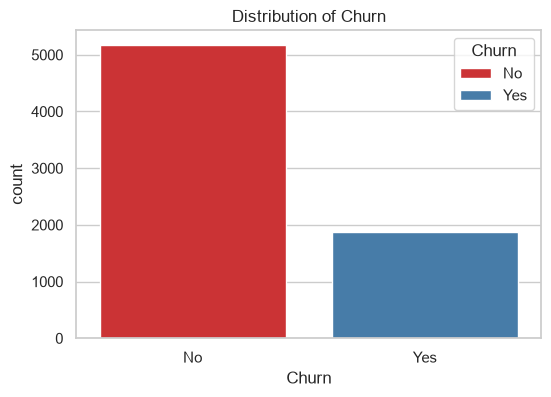

In [5]:
# Bar plot for the distribution of churn
fig,ax = plt.subplots(figsize = (6,4))
sns.countplot(data = df, x = "Churn", hue = "Churn", palette = "Set1", ax = ax )
ax.set_title("Distribution of Churn")
ax.legend(title = "Churn", labels = ["No","Yes"])

In [6]:
# Percentage of customer churned vs stayed
print(df["Churn"].value_counts(normalize=True)*100)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


The data is imbalance. Approximately 73% of the customers didnot churn, while 26% churned. Since the non churn class is much greater than churn class, the data is not evenly distributed.

## Data preprocessing
Machine learning model requires numerical data. I will drop unnecessary columns, handle the missing values, encode the target variable, and one-hot encode the categorial features. 

In [7]:
# 1. Drop the customerID because (it's unique for every person and has no predictive power.)
df = df.drop(columns = ['customerID'])

# 2. Drop the 11 rows with missing TotalCharges (it's less than 0.2% of the data, so safe to drop)
df = df.dropna(subset = ['TotalCharges'])

# 3. Convert the target variable Churn to 1(Yes) and 0(No)
df['Churn'] = df['Churn'].map({'Yes':1, 'No':0})

# 4. Convert categorical variables into dummy/indicator variables (One-Hot Encoding)
# We drop the first column to avoid the "dummy variable trap" (multicollinearity)
df_encoded = pd.get_dummies(df, drop_first=True)

print(f"Original Shape: {df.shape}")
print(f"Encoded Shape: {df_encoded.shape}")
display(df_encoded.head())

Original Shape: (7032, 20)
Encoded Shape: (7032, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False


Now that the data is fully numerical, I will separate it into Features(X) and Target(y) and split it into Training and Testing sets.

In [8]:
from sklearn.model_selection import train_test_split

# Separate Features and Target
X = df_encoded.drop(columns = ['Churn'])
y = df_encoded["Churn"]

# Train/Test split(80% train and 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify = y)

print(f"Training Set: {X_train.shape}")
print(f"Testing Set: {X_test.shape}")

Training Set: (5625, 30)
Testing Set: (1407, 30)


The number of columns increased because One-Hot Encoding converted categorical columns into multiple binary (0/1) columns. For example, a single column such as InternetService was split into separate columns like InternetService_Fiber optic and InternetService_No, allowing machine learning models to work with categorical data in numeric form.

## Baseline Modeling: Logistic Regression
I will train a Logistic Regression model, because dataset is imbalanced(73% No, 27% Yes), I will use "class_weight='balanced'" so the model doesn't just ignore the minority class. I will evaluate the model using Precision, Recall, and the Confusion Matrix.

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Initialize the model with class_weight='balanced'
log_ref = LogisticRegression(max_iter=1000, class_weight = 'balanced', random_state=42)

# 2. Train the model
log_ref.fit(X_train,y_train)

# 3. Make the prediction
y_pred = log_ref.predict(X_test)

# 4. Evaluate
print(f"Accuracy: {accuracy_score(y_test,y_pred)*100:.2f}%")
print("Classification Report:")
print(classification_report(y_test,y_pred))

print("\n Confusion matrix:")
print(confusion_matrix(y_test,y_pred))



Accuracy: 72.71%
Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.70      0.79      1033
           1       0.49      0.79      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407


 Confusion matrix:
[[726 307]
 [ 77 297]]


c:\Users\Asus\Desktop\Projects\project-02-customer-churn\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
